# CHE1147 Group 6 — Notebook 02: Preprocessing, Models and Evaluation

**Input:** `data/processed/tox21_clean.csv`, exported by `notebooks/01_EDA.ipynb`.  
**Five targets:** SR-ARE, SR-ATAD5, SR-HSE, SR-MMP, SR-p53.  
**Models:** Dummy (`prior`), Logistic Regression (LR), Random Forest (RF).  
**Main selection metric:** Average Precision (AP). Also report trapezoidal PR-AUC, ROC-AUC, accuracy, precision, recall, and F1.

### Decisions implemented
- **Keep-first deduplication happens only in Notebook 01.** This notebook does not deduplicate or merge labels.
- Exclude missing labels **separately for each assay**. Do not remove a compound globally because another assay is missing.
- Scaffold-aware, approximately 80/20 **outer train/test** separation; **five-fold scaffold-aware CV** on training data. The held-out test set never participates in model selection.
- LR: train-fold descriptor screening (impute missing values, remove constant/extreme descriptors, and correlation filter at `abs(r)>0.90`), then **forward feature selection** using a fixed `LogisticRegression(C=1, class_weight=None)` and **inner five-fold scaffold-aware CV**. Stop at a maximum of 30 selected features or AP gain below 0.005, keeping at least one feature. Finally tune LR over 12 configurations using outer five-fold CV.
- RF: descriptor screening without correlation or forward selection; **full 864-configuration GridSearchCV** across five scaffold-aware folds.
- The numerical preprocessing for each inner-SFS candidate is fitted **inside each inner training fold**. The initial *unsupervised* descriptor/correlation screening that defines the SFS candidate pool is fitted on the corresponding **outer training fold**, never on the held-out outer validation or final test data.
- Save **inference-only scikit-learn pipelines** (using built-in transformers), so Notebook 03 can load them **without importing custom Python classes**. Save selected feature names and split assignments separately.
- All figures are PNG only; results are stored under the project-stage-specific output folders.

**Runtime caution:** Caches are placed in your operating system temporary directory, outside your project and iCloud-synced folders. The production configuration performs 21,600 RF CV forest fits across five assays, **plus potentially very costly nested LR forward selection**. Run the SMOKE configuration first. GridSearchCV does not resume a partially interrupted assay. Each *completed* assay's LR and RF results are saved separately.

## 2.0 — Imports, project paths, and run configuration

Set `RUN_MODE = "smoke"` to check the workflow on **one assay with a reduced grid**. Change back to `"full"` for the approved production settings. The full RF grid is the default. `RUN_ASSAYS` can be restricted to one or more assays while testing. Keep `SEARCH_JOBS` small enough for your MacBook's available memory.

In [17]:
from __future__ import annotations

import json
import platform
import time
import tempfile
import hashlib
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdkit
import sklearn
from joblib import Memory, Parallel, delayed
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, auc, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedGroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# ------------------- USER CONFIGURATION -------------------
RUN_MODE = "full"            # Change to "smoke" to test first
RUN_ASSAYS = ["SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
RANDOM_SEED = 42
N_CV_FOLDS = 5
CORRELATION_THRESHOLD = 0.90
MAX_ABS_DESCRIPTOR_VALUE = 1e12  # training-fold numerical-safety filter
SFS_MAX_FEATURES = 30
SFS_MIN_IMPROVEMENT = 0.001 # minimum improvement to consider adding a feature
SFS_JOBS = 4                # parallelizes candidate evaluations, not LR outer grid
SEARCH_JOBS = 4             # RF GridSearchCV worker count; adjust to your RAM
MODEL_THRESHOLD = 0.50
FIGURE_DPI = 300

if RUN_MODE not in {"full", "smoke"}:
    raise ValueError('RUN_MODE must be "full" or "smoke".')
if RUN_MODE == "smoke":
    RUN_ASSAYS = [RUN_ASSAYS[0]]
    SFS_MAX_FEATURES = 2
    SFS_JOBS = 2
    SEARCH_JOBS = 2

ASSAYS = ["SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
if not RUN_ASSAYS or any(a not in ASSAYS for a in RUN_ASSAYS):
    raise ValueError("RUN_ASSAYS must contain one or more valid assay names.")

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data" / "processed" / "tox21_clean.csv").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError(
        "Cannot find data/processed/tox21_clean.csv. "
        "Run Notebook 01 from your CHE1147-Group-6 repository first."
    )
input_path = root / "data" / "processed" / "tox21_clean.csv"
fig_dir = root / "results" / "figures" / "Preprocessing_Models_Evaluation"
metrics_dir = root / "results" / "metrics" / "Preprocessing_Models_Evaluation"
models_dir = root / "results" / "models" / "Preprocessing_Models_Evaluation"
cache_root = (Path(tempfile.gettempdir()) / "che1147_lr_sfs"
              / hashlib.sha256(str(root).encode("utf-8")).hexdigest()[:12])
for directory in (fig_dir, metrics_dir, models_dir, cache_root):
    directory.mkdir(parents=True, exist_ok=True)

print("Root:", root)
print("Input:", input_path.relative_to(root))
print("Mode:", RUN_MODE, "| Assays:", RUN_ASSAYS)
print("scikit-learn:", sklearn.__version__, "| RDKit:", rdkit.__version__)
print("Python:", platform.python_version())

Root: /Users/weikun/Desktop/PhD/CHE1147-Group-6
Input: data/processed/tox21_clean.csv
Mode: full | Assays: ['SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']
scikit-learn: 1.7.2 | RDKit: 2026.03.6
Python: 3.10.21


## 2.1 — Read Notebook 01 output and define descriptor columns

The file has `canonical_smiles`, optionally `ID` and `SMILES`, five assay labels, and numeric RDKit descriptors. Every row is a unique canonical structure already selected under the **keep-first** deduplication policy.

In [2]:
data = pd.read_csv(input_path, low_memory=False)
metadata_columns = [c for c in ["ID", "SMILES", "canonical_smiles"] if c in data.columns]
required_columns = ["canonical_smiles", *ASSAYS]
missing_columns = [c for c in required_columns if c not in data.columns]
if missing_columns:
    raise ValueError(f"Missing required EDA export columns: {missing_columns}")
if data["canonical_smiles"].isna().any() or data["canonical_smiles"].duplicated().any():
    raise ValueError("Expected one nonmissing, unique canonical_smiles per row from Notebook 01.")

descriptor_cols = [c for c in data.columns if c not in set(metadata_columns + ASSAYS)]
if not descriptor_cols:
    raise ValueError("No descriptor columns found in tox21_clean.csv.")
for assay in ASSAYS:
    data[assay] = pd.to_numeric(data[assay], errors="coerce")
    data.loc[~data[assay].isin([0, 1]), assay] = np.nan
for c in descriptor_cols:
    data[c] = pd.to_numeric(data[c], errors="coerce")
data[descriptor_cols] = data[descriptor_cols].replace([np.inf, -np.inf], np.nan)
data = data.reset_index(drop=True)

print(f"Unique molecules: {len(data):,}")
print(f"RDKit descriptor columns: {len(descriptor_cols)}")
print("Label availability (per assay):")
display(pd.DataFrame({
    "Labeled": data[ASSAYS].notna().sum(),
    "Positive": data[ASSAYS].eq(1).sum(),
    "Prevalence among labeled": (data[ASSAYS].eq(1).sum() / data[ASSAYS].notna().sum()),
}).round(4))

Unique molecules: 8,041
RDKit descriptor columns: 217
Label availability (per assay):


,Labeled,Positive,Prevalence among labeled
SR-ARE,5611,847,0.1510
SR-ATAD5,5551,187,0.0337
SR-HSE,6408,326,0.0509
SR-MMP,4419,682,0.1543
SR-p53,5227,281,0.0538


## 2.2 — Generate Bemis–Murcko scaffold groups

Different molecules sharing a nonempty Murcko scaffold receive the same group ID. An acyclic molecule has an empty Murcko scaffold; instead of putting *all* acyclic molecules into one huge group, use its **canonical SMILES as a fallback group**. This preserves identical-molecule separation, but **does not guarantee structural separation between different acyclic molecules**; describe this limitation in the final paper.

In [3]:
def get_scaffold_group(canonical_smiles: str) -> str:
    mol = Chem.MolFromSmiles(canonical_smiles)
    if mol is None:
        raise ValueError(f"Invalid canonical SMILES in EDA export: {canonical_smiles!r}")
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    core = Chem.MolToSmiles(scaffold, isomericSmiles=False)
    return "SCAFFOLD::" + core if core else "ACYCLIC::" + canonical_smiles

if "__scaffold_group" in data.columns:
    raise ValueError("Reserved metadata column name already exists.")
data["__scaffold_group"] = data["canonical_smiles"].map(get_scaffold_group)
print("Unique scaffold groups:", data["__scaffold_group"].nunique())
print("Acyclic fallback molecules:", data["__scaffold_group"].str.startswith("ACYCLIC::").sum())

Unique scaffold groups: 4153
Acyclic fallback molecules: 1826


[16:30:13] WARNING: not removing hydrogen atom without neighbors


## 2.3 — Reliable grouped splits and diagnostics

We generate scaffold-aware five-fold partitions. The chosen test fold is the valid fold closest to 20% of samples, then closest in prevalence. This **uses only label counts**, not model performance. If no seed produces five valid class-containing folds, fail visibly rather than silently using random CV.

Each assay gets its own split because missing target labels differ across assays. **The same split is reused by Dummy, LR, and RF** within that assay.

In [5]:
# SECTION 2.3 — Scaffold-aware holdout and nested-CV-compatible splits.
# The holdout must also leave enough scaffold/label diversity for training CV.

def scaffold_class_support(y, groups):
    summary = pd.DataFrame({
        "scaffold": np.asarray(groups),
        "positive": np.asarray(y, dtype=int),
    }).groupby("scaffold")["positive"].agg(["size", "sum"])
    return {
        "scaffolds": len(summary),
        "positive_scaffolds": int(summary["sum"].gt(0).sum()),
        "negative_scaffolds": int((summary["size"] - summary["sum"]).gt(0).sum()),
        "largest_scaffold_n": int(summary["size"].max()),
    }


def grouped_folds(X, y, groups, n_splits=5, seed=42, max_seeds=100):
    """Find 2-class, scaffold-disjoint StratifiedGroupKFold folds.

    Never fall back to molecule-level random splitting or silently reduce folds.
    """
    y_arr = np.asarray(y, dtype=int)
    g_arr = np.asarray(groups)
    support = scaffold_class_support(y_arr, g_arr)
    if min(support["positive_scaffolds"], support["negative_scaffolds"]) < n_splits:
        raise ValueError(
            f"Cannot make {n_splits} two-class scaffold-disjoint folds: "
            f"{support}. At least {n_splits} distinct scaffold groups "
            "containing each class are required."
        )
    for try_seed in range(seed, seed + max_seeds):
        splitter = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=try_seed
        )
        folds = list(splitter.split(X, y_arr, groups=g_arr))
        if all(
            np.unique(y_arr[tr]).size == 2
            and np.unique(y_arr[va]).size == 2
            and not (set(g_arr[tr]) & set(g_arr[va]))
            for tr, va in folds
        ):
            return folds, try_seed
    raise ValueError(
        f"No valid {n_splits}-fold StratifiedGroupKFold split found "
        f"across {max_seeds} seeds. Scaffold statistics: {support}. "
        "A different scaffold-safe holdout, or a justified lower fold count, "
        "may be required; do not substitute random CV."
    )


def choose_holdout_with_training_cv(X, y, groups, n_splits=5, seed=42,
                                    outer_seed_trials=75, inner_seed_trials=100):
    """Search scaffold-safe holdouts, accepting only those supporting train CV.

    Test fold is selected using size/prevalence only, never model performance.
    """
    y = np.asarray(y, dtype=int)
    groups = np.asarray(groups)
    overall_prevalence = float(y.mean())
    overall_support = scaffold_class_support(y, groups)
    # With a held-out test set, outer-CV validation, and five-fold SFS
    # inside the remaining training partition, at least (5+2) separate
    # class-bearing scaffold groups are necessary for each class.
    if min(overall_support["positive_scaffolds"],
           overall_support["negative_scaffolds"]) < n_splits + 2:
        raise ValueError(
            f"Insufficient independent scaffolds for nested {n_splits}-fold "
            f"selection and a held-out test set: {overall_support}. "
            f"At least {n_splits + 2} scaffold groups containing each class "
            "are necessary for this exact nested scheme."
        )
    attempted = 0
    good_outer = 0
    failed_inner = 0
    first_inner_error = None

    for outer_seed in range(seed, seed + outer_seed_trials):
        outer = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=outer_seed
        )
        options = []
        for train_idx, test_idx in outer.split(X, y, groups=groups):
            if (np.unique(y[train_idx]).size != 2
                    or np.unique(y[test_idx]).size != 2):
                continue
            if set(groups[train_idx]) & set(groups[test_idx]):
                raise AssertionError("Scaffold leakage in outer split")
            score = (
                abs(len(test_idx) / len(y) - 1 / n_splits),
                abs(float(y[test_idx].mean()) - overall_prevalence),
            )
            options.append((score, train_idx, test_idx))
        options.sort(key=lambda item: item[0])
        good_outer += len(options)

        for _, train_idx, test_idx in options:
            attempted += 1
            y_train, g_train = y[train_idx], groups[train_idx]
            try:
                train_cv, cv_seed = grouped_folds(
                    X.iloc[train_idx], y_train, g_train,
                    n_splits=n_splits, seed=seed, max_seeds=inner_seed_trials,
                )
            except ValueError as exc:
                failed_inner += 1
                if first_inner_error is None:
                    first_inner_error = str(exc)
                continue

            # Preflight the exact inner grouped-CV scheme that forward selection
            # will use in each outer-CV training partition. Group counts alone
            # are necessary but do not guarantee SGKF can construct valid folds.
            can_run_sfs = True
            for cv_train_idx, _ in train_cv:
                try:
                    grouped_folds(
                        X.iloc[train_idx].iloc[cv_train_idx],
                        y_train[cv_train_idx], g_train[cv_train_idx],
                        n_splits=n_splits, seed=seed,
                        max_seeds=inner_seed_trials,
                    )
                except ValueError:
                    can_run_sfs = False
                    break
            if not can_run_sfs:
                failed_inner += 1
                continue

            return (train_idx, test_idx, outer_seed, train_cv, cv_seed,
                    attempted, failed_inner)

    raise ValueError(
        f"No valid outer holdout + inner {n_splits}-fold CV was found after "
        f"{outer_seed_trials} outer seeds ({good_outer} two-class holdout candidates, "
        f"{failed_inner} rejected by training CV). "
        f"All-data scaffold support: {scaffold_class_support(y, groups)}. "
        f"First inner error: {first_inner_error}. "
        "Please inspect scaffold label concentration before changing the CV design."
    )


assay_data = {}
all_split_rows = []
cv_diagnostic_rows = []
for assay in RUN_ASSAYS:
    observed = data.loc[data[assay].notna()].copy()
    y_all = observed[assay].astype(int).to_numpy()
    groups_all = observed["__scaffold_group"].to_numpy()
    X_all = observed[descriptor_cols + ["__scaffold_group"]].copy()

    print(f"Preparing {assay}: {len(y_all):,} labeled compounds, "
          f"scaffold support={scaffold_class_support(y_all, groups_all)}",
          flush=True)
    (train_idx, test_idx, test_seed, train_cv, cv_seed,
     attempted, rejected) = choose_holdout_with_training_cv(
        X_all, y_all, groups_all, N_CV_FOLDS, RANDOM_SEED
    )
    X_train = X_all.iloc[train_idx].reset_index(drop=True)
    X_test = X_all.iloc[test_idx].reset_index(drop=True)
    y_train, y_test = y_all[train_idx], y_all[test_idx]
    g_train, g_test = groups_all[train_idx], groups_all[test_idx]
    assert not (set(g_train) & set(g_test)), f"Scaffold leakage: {assay}"

    assay_data[assay] = dict(
        X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
        train_cv=train_cv,
        raw_train=observed.iloc[train_idx].reset_index(drop=True),
        raw_test=observed.iloc[test_idx].reset_index(drop=True),
    )
    for portion, ids in (("train", train_idx), ("test", test_idx)):
        for original_index in ids:
            all_split_rows.append(dict(
                assay=assay, split=portion,
                source_row=int(observed.index[original_index]),
                canonical_smiles=str(observed.iloc[original_index]["canonical_smiles"]),
                label=int(y_all[original_index]),
                scaffold_group=str(groups_all[original_index]),
            ))
    for fold_id, (tr, va) in enumerate(train_cv, 1):
        cv_diagnostic_rows.append(dict(
            assay=assay, fold=fold_id, n_train=len(tr), n_val=len(va),
            train_prevalence=float(np.mean(y_train[tr])),
            val_prevalence=float(np.mean(y_train[va])),
            n_train_groups=len(set(g_train[tr])),
            n_val_groups=len(set(g_train[va])),
            scaffold_overlap=len(set(g_train[tr]) & set(g_train[va])),
            seed=cv_seed,
        ))
    print(f"{assay}: train={len(y_train):,} (pos {np.mean(y_train):.3f}), "
          f"test={len(y_test):,} (pos {np.mean(y_test):.3f}), "
          f"scaffold overlap=0, test seed={test_seed}, CV seed={cv_seed}; "
          f"holdout candidates tried={attempted}, CV-rejected={rejected}",
          flush=True)

pd.DataFrame(all_split_rows).to_csv(metrics_dir / "split_assignments.csv", index=False)
pd.DataFrame(cv_diagnostic_rows).to_csv(metrics_dir / "cv_fold_diagnostics.csv", index=False)
display(pd.DataFrame(cv_diagnostic_rows).head(10))


Preparing SR-ARE: 5,611 labeled compounds, scaffold support={'scaffolds': 2989, 'positive_scaffolds': 526, 'negative_scaffolds': 2572, 'largest_scaffold_n': 1179}
SR-ARE: train=4,466 (pos 0.148), test=1,145 (pos 0.162), scaffold overlap=0, test seed=42, CV seed=42; holdout candidates tried=1, CV-rejected=0
Preparing SR-ATAD5: 5,551 labeled compounds, scaffold support={'scaffolds': 3032, 'positive_scaffolds': 130, 'negative_scaffolds': 2935, 'largest_scaffold_n': 1129}
SR-ATAD5: train=4,378 (pos 0.033), test=1,173 (pos 0.036), scaffold overlap=0, test seed=42, CV seed=42; holdout candidates tried=1, CV-rejected=0
Preparing SR-HSE: 6,408 labeled compounds, scaffold support={'scaffolds': 3371, 'positive_scaffolds': 235, 'negative_scaffolds': 3194, 'largest_scaffold_n': 1316}
SR-HSE: train=3,839 (pos 0.054), test=2,569 (pos 0.047), scaffold overlap=0, test seed=42, CV seed=42; holdout candidates tried=5, CV-rejected=4
Preparing SR-MMP: 4,419 labeled compounds, scaffold support={'scaffolds'

,assay,fold,n_train,n_val,train_prevalence,val_prevalence,n_train_groups,n_val_groups,scaffold_overlap,seed
0,SR-ARE,1,4458,8,0.148273,0.125000,2236,8,0,42
1,SR-ARE,2,3586,880,0.150028,0.140909,1679,565,0,42
2,SR-ARE,3,3704,762,0.137689,0.199475,1690,554,0,42
3,SR-ARE,4,3656,810,0.145788,0.159259,1694,550,0,42
4,SR-ARE,5,2460,2006,0.165041,0.127617,1677,567,0,42
5,SR-ATAD5,1,3516,862,0.031854,0.038283,1709,568,0,42
6,SR-ATAD5,2,3570,808,0.033333,0.032178,1709,568,0,42
7,SR-ATAD5,3,4365,13,0.032990,0.076923,2268,9,0,42
8,SR-ATAD5,4,2381,1997,0.036959,0.028543,1713,564,0,42
9,SR-ATAD5,5,3680,698,0.031793,0.040115,1709,568,0,42


## 2.4 — Training-fold descriptor screening

This transformer works only on features in its `.fit()` data, never on validation/test data. It removes all-missing, constant, and very large-magnitude descriptors (numerical-safety cutoff), and optionally removes correlated descriptors at `abs(r)>0.90`. Imputation for correlation calculation uses **training-fold medians only**; the actual LR/RF pipelines separately fit their imputers. This avoids globally deleting rows with missing descriptors.

The numerical cutoff is not a chemical selection criterion. Its purpose is to avoid invalid/overflowing values (e.g. extreme RDKit descriptors); we record exactly which columns were removed.

In [6]:
class DescriptorScreen(BaseEstimator, TransformerMixin):
    def __init__(self, correlation_threshold=None, max_abs=1e12):
        self.correlation_threshold = correlation_threshold
        self.max_abs = max_abs

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("DescriptorScreen needs a DataFrame with named descriptors.")
        names = list(X.columns)
        working = X.apply(pd.to_numeric, errors="coerce").replace(
            [np.inf, -np.inf], np.nan
        )
        all_missing = [c for c in names if working[c].notna().sum() == 0]
        constant = [c for c in names if working[c].nunique(dropna=True) <= 1]
        too_large = [c for c in names if working[c].abs().max(skipna=True) > self.max_abs]
        excluded = set(all_missing + constant + too_large)
        candidates = [c for c in names if c not in excluded]
        if not candidates:
            raise ValueError("No numerically usable descriptor remains.")
        corr_dropped = []
        if self.correlation_threshold is not None:
            imputed = working[candidates].fillna(working[candidates].median())
            correlation = imputed.corr().abs().fillna(0.0)
            selected = []
            for name in candidates:
                if any(correlation.loc[name, kept] > self.correlation_threshold
                       for kept in selected):
                    corr_dropped.append(name)
                else:
                    selected.append(name)
            candidates = selected
        self.selected_columns_ = candidates
        self.removed_reasons_ = {
            "all_missing": all_missing,
            "constant_or_single_observed_value": constant,
            "numerically_extreme": too_large,
            "high_correlation": corr_dropped,
        }
        self.feature_names_in_ = np.asarray(names, dtype=object)
        return self

    def transform(self, X):
        return X.loc[:, self.selected_columns_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.selected_columns_, dtype=object)

## 2.5 — Forward selection using a **fixed** Logistic Regression configuration

**Nested structure:** For every *outer CV training fold*, the selector fits its own unsupervised descriptor screen on that training fold; it then evaluates the candidate additions using *inner* scaffold-disjoint five-fold CV. Each inner fold fits its own `SimpleImputer` and `StandardScaler` using **inner training data only**. All candidates use LR with **`C=1.0`, `class_weight=None`, L2, `liblinear`**, evaluated by **AP**. This fixed internal LR is distinct from the final tuned LR.

The selector is implemented here (inside the notebook), not in a `.py` utility file. To keep this potentially expensive search practical, numerical transformations are cached once per inner fold and reusable across candidate subsets. Candidate-level fitting is parallelized by `SFS_JOBS`.

**Stop rule:** Always keep at least one feature. On later steps, stop when the best next feature raises mean inner-CV AP by less than 0.005, or when 30 features are selected. The selected subset can change between outer CV folds; only the final full-training refit's subset is exported.

In [7]:
def _score_feature_subset(selected_indices, folded, seed):
    """Mean inner-CV AP; folded arrays were scaled using each inner TRAIN partition."""
    fold_scores = []
    for x_train_fold, x_valid_fold, y_train_fold, y_valid_fold in folded:
        model = LogisticRegression(
            penalty="l2", C=1.0, class_weight=None, solver="liblinear",
            max_iter=2000, random_state=seed,
        )
        model.fit(x_train_fold[:, selected_indices], y_train_fold)
        prob = model.predict_proba(x_valid_fold[:, selected_indices])[:, 1]
        fold_scores.append(average_precision_score(y_valid_fold, prob))
    return float(np.mean(fold_scores))


class ScaffoldForwardSelector(BaseEstimator, TransformerMixin):
    def __init__(self, correlation_threshold=0.90, max_abs=1e12,
                 max_features=30, min_improvement=0.005,
                 inner_folds=5, random_state=42, n_jobs=4):
        self.correlation_threshold = correlation_threshold
        self.max_abs = max_abs
        self.max_features = max_features
        self.min_improvement = min_improvement
        self.inner_folds = inner_folds
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        if "__scaffold_group" not in X.columns:
            raise ValueError("Required __scaffold_group metadata is missing.")
        group_values = X["__scaffold_group"].to_numpy()
        raw = X.drop(columns="__scaffold_group")
        y = np.asarray(y, dtype=int)
        self.screen_ = DescriptorScreen(
            correlation_threshold=self.correlation_threshold,
            max_abs=self.max_abs,
        ).fit(raw)
        candidate_columns = list(self.screen_.selected_columns_)
        raw_values = self.screen_.transform(raw).to_numpy(dtype=np.float64)
        folds, self.inner_seed_ = grouped_folds(
            raw_values, y, group_values, self.inner_folds, self.random_state
        )
        folded = []
        for tr, va in folds:
            # Imputer and scaler are trained ONLY on this inner training fold.
            imputer = SimpleImputer(strategy="median", keep_empty_features=True)
            scaler = StandardScaler()
            inner_tr = scaler.fit_transform(imputer.fit_transform(raw_values[tr]))
            inner_va = scaler.transform(imputer.transform(raw_values[va]))
            folded.append((inner_tr, inner_va, y[tr], y[va]))

        selected_indices = []
        remaining_indices = list(range(len(candidate_columns)))
        baseline = float(np.mean([np.mean(y[va]) for _, va in folds]))
        last_score = baseline
        self.history_ = []
        for step in range(min(self.max_features, len(candidate_columns))):
            print(f"[SFS] step {step+1}: evaluating {len(remaining_indices)} candidate features", flush=True)
            scores = Parallel(n_jobs=self.n_jobs, prefer="threads") (
                delayed(_score_feature_subset)(selected_indices + [i], folded, self.random_state)
                for i in remaining_indices
            )
            winner_pos = int(np.argmax(scores))
            winner_index = remaining_indices[winner_pos]
            best_score = float(scores[winner_pos])
            gain = best_score - last_score
            if step > 0 and gain < self.min_improvement:
                print(f"[SFS] stop: best AP improvement {gain:.4f} < {self.min_improvement:.4f}", flush=True)
                break
            print(f"[SFS] selected {candidate_columns[winner_index]}: mean inner AP={best_score:.4f}, gain={gain:.4f}", flush=True)
            selected_indices.append(winner_index)
            remaining_indices.remove(winner_index)
            self.history_.append(dict(
                step=step + 1, descriptor=candidate_columns[winner_index],
                mean_inner_cv_ap=best_score, improvement=gain,
                candidates_evaluated=len(scores),
            ))
            last_score = best_score

        self.selected_columns_ = [candidate_columns[i] for i in selected_indices]
        self.n_features_selected_ = len(self.selected_columns_)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        return X.loc[:, self.selected_columns_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.selected_columns_, dtype=object)

print("Scaffold-aware SFS class defined.")

Scaffold-aware SFS class defined.


## 2.6 — Model pipelines and confirmed search grids

The LR pipeline caches its **selector output** between candidate `C`/`class_weight` combinations. This is safe because the SFS estimator uses fixed `C=1` internally and no final-model hyperparameter enters the selection. `GridSearchCV(n_jobs=1)` for LR allows sequential reuse of this cache; **SFS candidate evaluation itself is parallelized**. RF searches the **full 864-combination grid**, with model-level parallelism disabled and outer CV fit-level parallelism controlled by `SEARCH_JOBS`.

In [18]:
LR_PARAM_GRID = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}
RF_PARAM_GRID = {
    "model__n_estimators": [200, 400, 600],
    "model__max_depth": [None, 8, 16, 32],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": ["sqrt", 0.5, 0.8],
    "model__class_weight": [None, "balanced_subsample"],
}

if RUN_MODE == "smoke":
    # TEST-ONLY settings; the full production grids above are not modified.
    lr_grid_to_run = {"model__C": [1], "model__class_weight": [None]}
    rf_grid_to_run = {
        "model__n_estimators": [20],
        "model__max_depth": [8],
        "model__min_samples_split": [2],
        "model__min_samples_leaf": [1],
        "model__max_features": ["sqrt"],
        "model__class_weight": [None],
    }
else:
    lr_grid_to_run = LR_PARAM_GRID
    rf_grid_to_run = RF_PARAM_GRID

assert len(list(ParameterGrid(LR_PARAM_GRID))) == 12
assert len(list(ParameterGrid(RF_PARAM_GRID))) == 864
print("LR combinations:", len(list(ParameterGrid(lr_grid_to_run))))
print("RF combinations:", len(list(ParameterGrid(rf_grid_to_run))))


def make_lr_pipeline(cache_location):
    return Pipeline([
        ("select", ScaffoldForwardSelector(
            correlation_threshold=CORRELATION_THRESHOLD,
            max_abs=MAX_ABS_DESCRIPTOR_VALUE,
            max_features=SFS_MAX_FEATURES,
            min_improvement=SFS_MIN_IMPROVEMENT,
            inner_folds=N_CV_FOLDS,
            random_state=RANDOM_SEED,
            n_jobs=SFS_JOBS,
        )),
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            solver="liblinear", penalty="l2", max_iter=2000,
            random_state=RANDOM_SEED,
        )),
    ], memory=Memory(location=str(cache_location), verbose=0))


def make_rf_pipeline():
    return Pipeline([
        ("screen", DescriptorScreen(
            correlation_threshold=None, max_abs=MAX_ABS_DESCRIPTOR_VALUE,
        )),
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("model", RandomForestClassifier(
            random_state=RANDOM_SEED, n_jobs=1,
        )),
    ])

LR combinations: 12
RF combinations: 864


## 2.7 — Shared evaluation functions and portable export pipelines

Use AP as the selection metric and evaluate on the held-out test set only **after** tuning. Predictions from the final refit and the exported built-in pipeline must agree. Saved models use only standard scikit-learn transformers and accept a DataFrame containing the original named RDKit descriptors. Notebook 03 can load them with `joblib.load()` without redefining `ScaffoldForwardSelector` or `DescriptorScreen`.

In [9]:
def model_metrics(assay, name, y_true, probs, preds, y_train):
    p, r, _ = precision_recall_curve(y_true, probs)
    return dict(
        assay=assay, model=name, n_test=len(y_true),
        n_test_positive=int(np.sum(y_true)),
        train_prevalence=float(np.mean(y_train)),
        test_prevalence=float(np.mean(y_true)),
        ap=float(average_precision_score(y_true, probs)),
        trapezoidal_pr_auc=float(auc(r, p)),
        roc_auc=float(roc_auc_score(y_true, probs)),
        accuracy=float(accuracy_score(y_true, preds)),
        precision=float(precision_score(y_true, preds, zero_division=0)),
        recall=float(recall_score(y_true, preds, zero_division=0)),
        f1=float(f1_score(y_true, preds, zero_division=0)),
        threshold=MODEL_THRESHOLD,
        run_mode=RUN_MODE,
    )


def append_predictions(assay, model_name, test_meta, y_true, prob, pred):
    table = pd.DataFrame(dict(
        assay=assay, model=model_name,
        canonical_smiles=test_meta["canonical_smiles"].to_numpy(),
        scaffold_group=test_meta["__scaffold_group"].to_numpy(),
        y_true=y_true, predicted_probability=prob, predicted_class=pred,
    ))
    if "ID" in test_meta.columns:
        table.insert(3, "ID", test_meta["ID"].to_numpy())
    table.to_csv(metrics_dir / f"predictions_{assay}_{model_name}.csv", index=False)
    return table


def portable_lr_pipeline(selected_features, best_params, X_train_raw, y_train):
    preprocessing = ColumnTransformer([
        ("selected_descriptors", Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler()),
        ]), list(selected_features)),
    ], remainder="drop")
    model = LogisticRegression(
        solver="liblinear", penalty="l2", max_iter=2000,
        random_state=RANDOM_SEED,
        C=best_params["model__C"],
        class_weight=best_params["model__class_weight"],
    )
    return Pipeline([("preprocess", preprocessing), ("model", model)]).fit(
        X_train_raw, y_train
    )


def portable_rf_pipeline(selected_features, best_params, X_train_raw, y_train):
    preprocessing = ColumnTransformer([
        ("selected_descriptors", SimpleImputer(
            strategy="median", keep_empty_features=True
        ), list(selected_features)),
    ], remainder="drop")
    rf_args = {k.replace("model__", ""): v for k, v in best_params.items()}
    model = RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=1, **rf_args)
    return Pipeline([("preprocess", preprocessing), ("model", model)]).fit(
        X_train_raw, y_train
    )


def save_json(path, content):
    def to_jsonable(o):
        if isinstance(o, (np.integer,)):
            return int(o)
        if isinstance(o, (np.floating,)):
            return float(o)
        if isinstance(o, Path):
            return str(o)
        raise TypeError(f"Cannot JSON encode {type(o)}")
    path.write_text(json.dumps(content, indent=2, default=to_jsonable), encoding="utf-8")


def save_model_summary(assay, model_name, y_train, y_test, pred, prob, test_meta):
    row = model_metrics(assay, model_name, y_test, prob, pred, y_train)
    pd.DataFrame([row]).to_csv(metrics_dir / f"metrics_{assay}_{model_name}.csv", index=False)
    append_predictions(assay, model_name, test_meta, y_test, prob, pred)
    print(f"{assay:>8} {model_name:>5}: AP={row['ap']:.4f}, "
          f"ROC-AUC={row['roc_auc']:.4f}, F1={row['f1']:.4f}")
    return row

## 2.8 — DummyClassifier (training prevalence baseline)

No descriptor preprocessing, tuning, or forward selection is needed. `strategy="prior"` predicts a constant positive probability equal to the **training prevalence**. Its AP equals the **held-out test prevalence**, and its ROC-AUC is 0.5 when both classes are present.

In [10]:
for assay in RUN_ASSAYS:
    bundle = assay_data[assay]
    Xtr, Xte = bundle["X_train"], bundle["X_test"]
    ytr, yte = bundle["y_train"], bundle["y_test"]
    dummy = DummyClassifier(strategy="prior").fit(Xtr[descriptor_cols], ytr)
    probs = dummy.predict_proba(Xte[descriptor_cols])[:, 1]
    preds = dummy.predict(Xte[descriptor_cols])
    save_model_summary(
        assay, "Dummy", ytr, yte, preds, probs, bundle["raw_test"]
    )
    joblib.dump(dummy, models_dir / f"Dummy_{assay}.joblib")
    assert np.isclose(average_precision_score(yte, probs), np.mean(yte))

  SR-ARE Dummy: AP=0.1616, ROC-AUC=0.5000, F1=0.0000
SR-ATAD5 Dummy: AP=0.0358, ROC-AUC=0.5000, F1=0.0000
  SR-HSE Dummy: AP=0.0467, ROC-AUC=0.5000, F1=0.0000
  SR-MMP Dummy: AP=0.1448, ROC-AUC=0.5000, F1=0.0000
  SR-p53 Dummy: AP=0.0383, ROC-AUC=0.5000, F1=0.0000


## 2.9 — Logistic Regression: nested scaffold-aware SFS + outer GridSearchCV

**Run this cell after the smoke test is successful.** The selector uses fixed LR `C=1`; the outer grid tunes the final model's `C` and class weights using five-fold AP. `memory` lets the twelve hyperparameter settings reuse identical feature-selection work within each outer fold. We save fitted selected descriptor names, score history, CV results and a portable inference pipeline for each *completed* assay. SFS can still be very expensive.

In [19]:
for assay in RUN_ASSAYS:
    print("\n" + "=" * 65)
    print(f"Logistic Regression + forward selection: {assay}")
    started = time.perf_counter()
    bundle = assay_data[assay]
    Xtr, Xte = bundle["X_train"], bundle["X_test"]
    ytr, yte = bundle["y_train"], bundle["y_test"]
    memory = Memory(location=str(cache_root / assay), verbose=0)

    lr_search = GridSearchCV(
        estimator=make_lr_pipeline(cache_root / assay),
        param_grid=lr_grid_to_run,
        scoring="average_precision",
        cv=bundle["train_cv"],
        n_jobs=1,  # ensures cache is reused across all hyperparameter combinations
        verbose=1,
        refit=True,
        return_train_score=False,
        error_score="raise",
    )
    lr_search.fit(Xtr, ytr)
    fitted_selector = lr_search.best_estimator_.named_steps["select"]
    chosen = list(fitted_selector.selected_columns_)
    print(f"Selected {len(chosen)} LR descriptors for {assay}")
    print("Best LR hyperparameters:", lr_search.best_params_)
    print("Best mean CV AP:", round(float(lr_search.best_score_), 5))

    # Train a PORTABLE inference-only pipeline (no notebook-defined custom classes).
    portable = portable_lr_pipeline(chosen, lr_search.best_params_, Xtr, ytr)
    prob_ref = lr_search.best_estimator_.predict_proba(Xte)[:, 1]
    prob_portable = portable.predict_proba(Xte)[:, 1]
    np.testing.assert_allclose(prob_ref, prob_portable, rtol=1e-6, atol=1e-8)
    preds = (prob_portable >= MODEL_THRESHOLD).astype(int)
    save_model_summary(
        assay, "LR", ytr, yte, preds, prob_portable, bundle["raw_test"]
    )
    joblib.dump(portable, models_dir / f"LR_{assay}.joblib")
    pd.DataFrame({
        "assay": assay, "model": "LR", "selection_order": range(1, len(chosen) + 1),
        "descriptor": chosen,
    }).to_csv(metrics_dir / f"selected_features_LR_{assay}.csv", index=False)
    pd.DataFrame(fitted_selector.history_).to_csv(
        metrics_dir / f"sfs_history_{assay}.csv", index=False
    )
    pd.DataFrame(lr_search.cv_results_).to_csv(
        metrics_dir / f"cv_results_LR_{assay}.csv", index=False
    )
    save_json(metrics_dir / f"best_hyperparameters_LR_{assay}.json", {
        "assay": assay, "model": "LR", "best_params": lr_search.best_params_,
        "mean_cv_ap": float(lr_search.best_score_),
        "selected_features": chosen,
        "selected_feature_count": len(chosen),
        "sfs_fixed_lr_c": 1.0,
        "sfs_fixed_lr_class_weight": None,
        "sfs_max_features": SFS_MAX_FEATURES,
        "sfs_improvement_threshold": SFS_MIN_IMPROVEMENT,
        "screen_removed_reasons": fitted_selector.screen_.removed_reasons_,
        "run_mode": RUN_MODE,
    })
    print(f"LR finished for {assay} in {(time.perf_counter() - started)/60:.1f} min")
    # Clear cached selector transforms between assays to control disk usage.
    memory.clear(warn=False)


Logistic Regression + forward selection: SR-ARE
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[SFS] step 1: evaluating 180 candidate features
[SFS] selected BertzCT: mean inner AP=0.3983, gain=0.2482
[SFS] step 2: evaluating 179 candidate features
[SFS] selected NumAromaticRings: mean inner AP=0.4150, gain=0.0167
[SFS] step 3: evaluating 178 candidate features
[SFS] selected fr_allylic_oxid: mean inner AP=0.4264, gain=0.0114
[SFS] step 4: evaluating 177 candidate features
[SFS] selected MolLogP: mean inner AP=0.4441, gain=0.0177
[SFS] step 5: evaluating 176 candidate features
[SFS] selected PEOE_VSA2: mean inner AP=0.4555, gain=0.0114
[SFS] step 6: evaluating 175 candidate features
[SFS] selected SMR_VSA7: mean inner AP=0.4625, gain=0.0070
[SFS] step 7: evaluating 174 candidate features
[SFS] selected fr_epoxide: mean inner AP=0.4687, gain=0.0062
[SFS] step 8: evaluating 173 candidate features
[SFS] selected FpDensityMorgan1: mean inner AP=0.4736, gain=0.0048
[SFS] step

## 2.10 — Random Forest: RandomizedSearchCV (100 Combinations)

Random Forest hyperparameters are optimized using `RandomizedSearchCV`, which randomly samples 100 configurations from the full search space of 864 possible combinations. Each configuration is evaluated using five-fold scaffold-aware stratified cross-validation, with **Average Precision (AP)** as the primary optimization metric.

- **100 configurations per assay**
- **5 CV folds per configuration**
- **500 cross-validation fits per assay**
- **2,500 cross-validation fits across all five assays**, excluding final refits

Randomized search reduces computational cost while retaining coverage of the original hyperparameter ranges. The search uses controlled CPU parallelism and saves results after each completed assay. If interrupted during an assay, the unfinished search cannot automatically resume. Final model evaluation is performed on the held-out test set, which is not used during hyperparameter selection.

In [14]:
for assay in RUN_ASSAYS:
    print("\n" + "=" * 65)
    print(f"Random Forest randomized tuning: {assay}")
    started = time.perf_counter()
    bundle = assay_data[assay]
    Xtr, Xte = bundle["X_train"], bundle["X_test"]
    ytr, yte = bundle["y_train"], bundle["y_test"]
    rf_search = RandomizedSearchCV(
        estimator=make_rf_pipeline(),
        param_distributions=rf_grid_to_run,
        n_iter=100,
        scoring="average_precision",
        cv=bundle["train_cv"],
        n_jobs=SEARCH_JOBS,
        pre_dispatch=SEARCH_JOBS,
        verbose=10,
        refit=True,
        random_state=42,
        return_train_score=False,
        error_score="raise",
    )
    rf_search.fit(Xtr[descriptor_cols], ytr)
    fitted_screen = rf_search.best_estimator_.named_steps["screen"]
    chosen = list(fitted_screen.selected_columns_)
    portable = portable_rf_pipeline(chosen, rf_search.best_params_, Xtr[descriptor_cols], ytr)
    prob_ref = rf_search.best_estimator_.predict_proba(Xte[descriptor_cols])[:, 1]
    prob_portable = portable.predict_proba(Xte[descriptor_cols])[:, 1]
    np.testing.assert_allclose(prob_ref, prob_portable, rtol=1e-6, atol=1e-8)
    preds = (prob_portable >= MODEL_THRESHOLD).astype(int)
    save_model_summary(
        assay, "RF", ytr, yte, preds, prob_portable, bundle["raw_test"]
    )
    joblib.dump(portable, models_dir / f"RF_{assay}.joblib")
    pd.DataFrame({
        "assay": assay, "model": "RF", "descriptor": chosen,
    }).to_csv(metrics_dir / f"selected_features_RF_{assay}.csv", index=False)
    pd.DataFrame(rf_search.cv_results_).to_csv(
        metrics_dir / f"cv_results_RF_{assay}.csv", index=False
    )
    save_json(metrics_dir / f"best_hyperparameters_RF_{assay}.json", {
        "assay": assay, "model": "RF", "best_params": rf_search.best_params_,
        "mean_cv_ap": float(rf_search.best_score_),
        "selected_features": chosen,
        "screen_removed_reasons": fitted_screen.removed_reasons_,
        "run_mode": RUN_MODE,
    })
    print(f"RF best params: {rf_search.best_params_}")
    print(f"RF mean CV AP: {rf_search.best_score_:.5f}")
    print(f"RF finished for {assay} in {(time.perf_counter() - started)/60:.1f} min")


Random Forest randomized tuning: SR-ARE
Fitting 5 folds for each of 100 candidates, totalling 500 fits


/Users/weikun/.local/share/uv/python/cpython-3.10.21-macos-aarch64-none/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/weikun/.local/share/uv/python/cpython-3.10.21-macos-aarch64-none/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/weikun/.local/share/uv/python/cpython-3.10.21-macos-aarch64-none/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/late

[CV 2/5; 1/100] START model__class_weight=None, model__max_depth=8, model__max_features=0.8, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200[CV 1/5; 1/100] START model__class_weight=None, model__max_depth=8, model__max_features=0.8, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200

[CV 4/5; 1/100] START model__class_weight=None, model__max_depth=8, model__max_features=0.8, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200[CV 3/5; 1/100] START model__class_weight=None, model__max_depth=8, model__max_features=0.8, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200

[CV 2/5; 1/100] END model__class_weight=None, model__max_depth=8, model__max_features=0.8, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200;, score=0.476 total time=  11.6s
[CV 5/5; 1/100] START model__class_weight=None, model__max_depth=8, model__max_features=0.8, model__min_sampl

## 2.11 — Combine results, generate PR/ROC curves, and confusion matrices

Run after the training cells have generated predictions. Each assay gets PNG-only PR/ROC curves; the no-skill PR reference is the **test positive prevalence**, not a misleading trapezoidal DummyClassifier line. Cross-assay AP values must be interpreted in context because label prevalence varies.

,assay,model,n_test,test_prevalence,ap,trapezoidal_pr_auc,roc_auc,accuracy,precision,recall,f1
0,SR-ARE,Dummy,1145,0.1616,0.1616,0.5808,0.5000,0.8384,0.0000,0.0000,0.0000
1,SR-ARE,LR,1145,0.1616,0.3518,0.3472,0.6944,0.8437,0.5882,0.1081,0.1826
2,SR-ARE,RF,1145,0.1616,0.5465,0.5450,0.8355,0.8585,0.7447,0.1892,0.3017
3,SR-ATAD5,Dummy,1173,0.0358,0.0358,0.5179,0.5000,0.9642,0.0000,0.0000,0.0000
4,SR-ATAD5,LR,1173,0.0358,0.0640,0.0616,0.7143,0.9642,0.0000,0.0000,0.0000
5,SR-ATAD5,RF,1173,0.0358,0.1904,0.1766,0.8461,0.9420,0.1750,0.1667,0.1707
6,SR-HSE,Dummy,2569,0.0467,0.0467,0.5234,0.5000,0.9533,0.0000,0.0000,0.0000
7,SR-HSE,LR,2569,0.0467,0.1704,0.1659,0.7543,0.9517,0.2500,0.0167,0.0312
8,SR-HSE,RF,2569,0.0467,0.2401,0.2361,0.7612,0.9552,0.6667,0.0833,0.1481
9,SR-MMP,Dummy,891,0.1448,0.1448,0.5724,0.5000,0.8552,0.0000,0.0000,0.0000


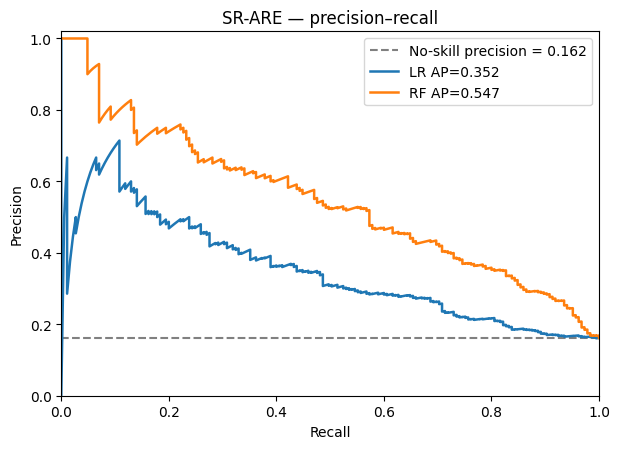

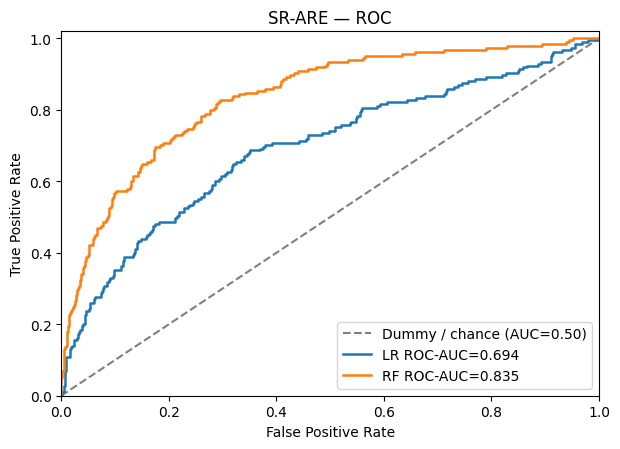

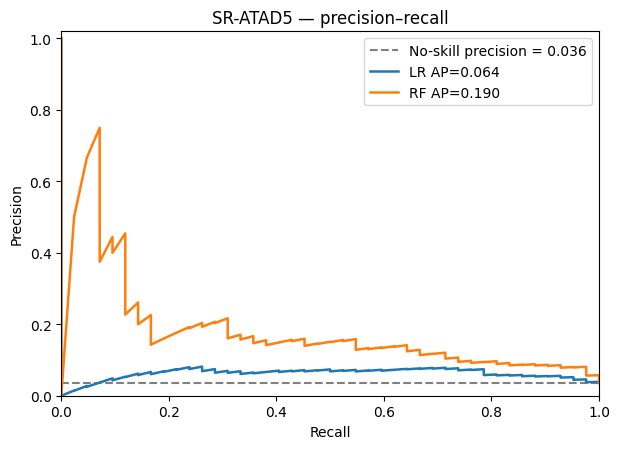

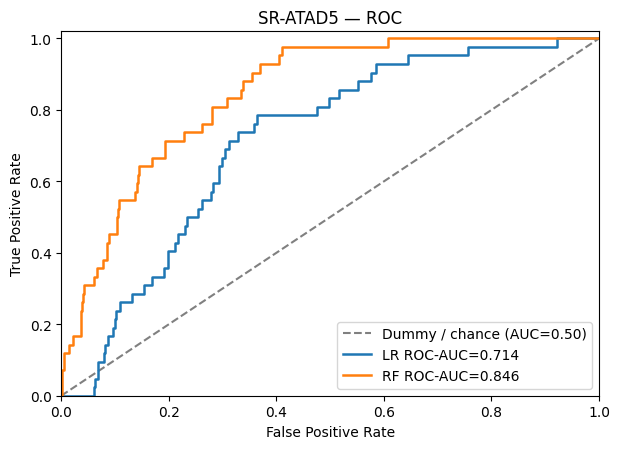

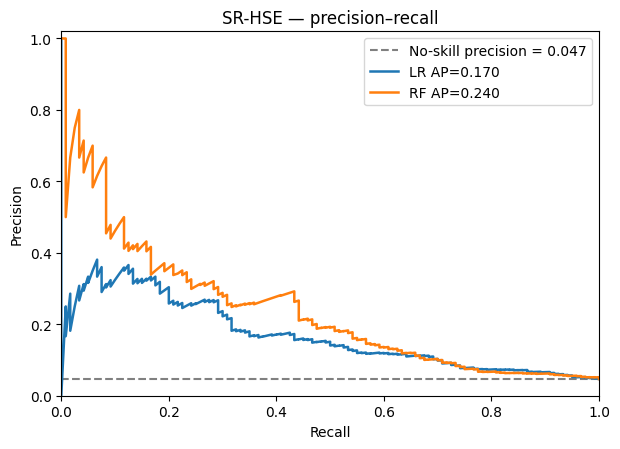

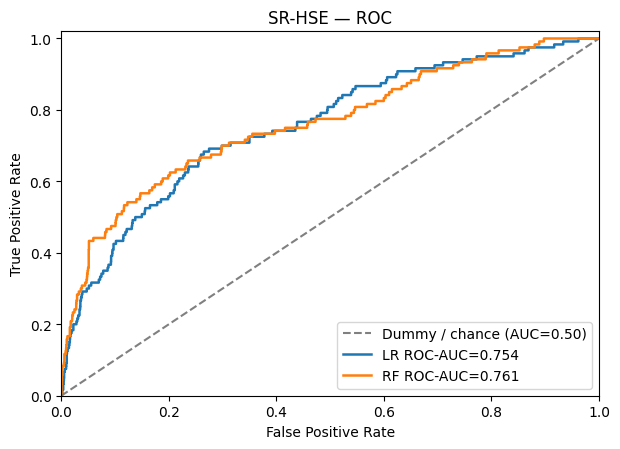

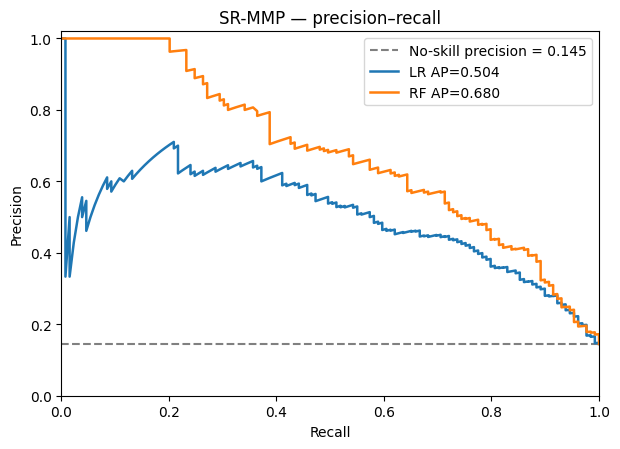

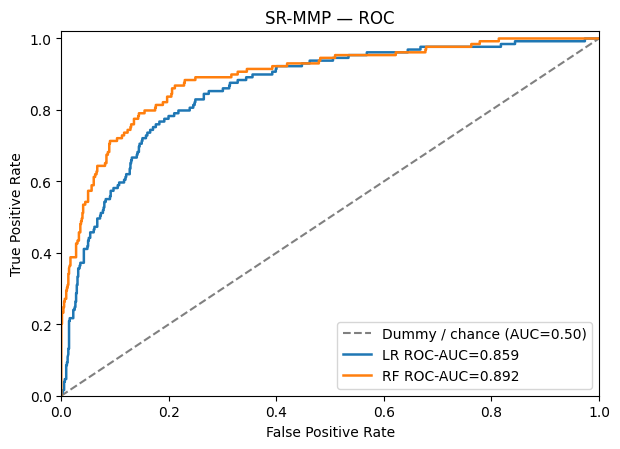

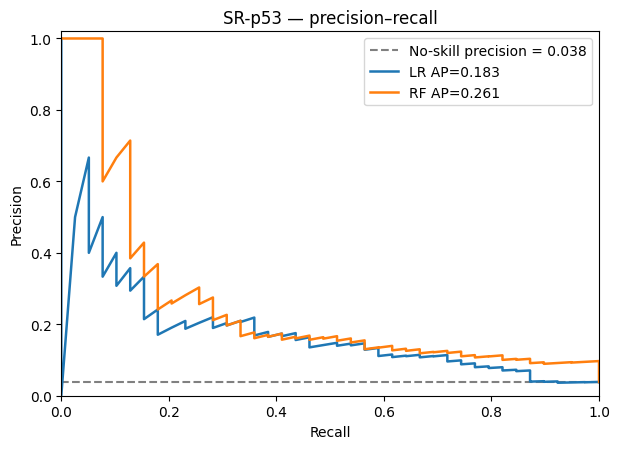

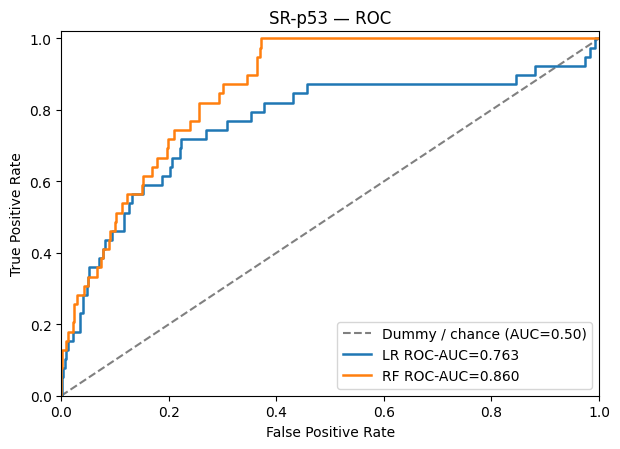

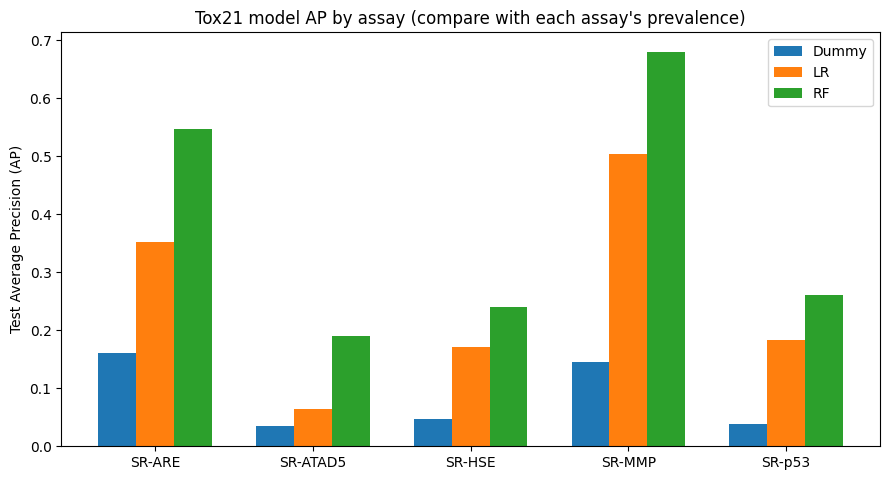

In [20]:
results_rows = []
for assay in RUN_ASSAYS:
    for model_name in ["Dummy", "LR", "RF"]:
        path = metrics_dir / f"metrics_{assay}_{model_name}.csv"
        if path.is_file():
            current = pd.read_csv(path)
            current = current.loc[current["run_mode"].eq(RUN_MODE)]
            results_rows.extend(current.to_dict("records"))
if not results_rows:
    raise RuntimeError("No completed metrics files found. Run the model cells above.")
performance = pd.DataFrame(results_rows)
performance.to_csv(metrics_dir / "model_performance.csv", index=False)
display(performance[[
    "assay", "model", "n_test", "test_prevalence", "ap", "trapezoidal_pr_auc",
    "roc_auc", "accuracy", "precision", "recall", "f1",
]].round(4))

for assay in RUN_ASSAYS:
    model_tables = {}
    for model_name in ["Dummy", "LR", "RF"]:
        path = metrics_dir / f"predictions_{assay}_{model_name}.csv"
        metric_path = metrics_dir / f"metrics_{assay}_{model_name}.csv"
        if path.exists() and metric_path.exists():
            recorded = pd.read_csv(metric_path)
            if recorded["run_mode"].iloc[0] == RUN_MODE:
                model_tables[model_name] = pd.read_csv(path)
    if not model_tables:
        continue

    truth = next(iter(model_tables.values()))["y_true"].to_numpy(dtype=int)
    baseline = float(np.mean(truth))
    fig, ax = plt.subplots(figsize=(6.3, 4.6))
    ax.axhline(baseline, color="gray", linestyle="--", label=f"No-skill precision = {baseline:.3f}")
    for name in ["LR", "RF"]:
        if name not in model_tables:
            continue
        row = model_tables[name]
        assert np.array_equal(truth, row["y_true"].to_numpy(dtype=int))
        prob = row["predicted_probability"].to_numpy(dtype=float)
        precision, recall, _ = precision_recall_curve(truth, prob)
        score = average_precision_score(truth, prob)
        ax.plot(recall, precision, linewidth=1.8, label=f"{name} AP={score:.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", title=f"{assay} — precision–recall")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(loc="best")
    fig.tight_layout()
    fig.savefig(fig_dir / f"PR_curve_{assay}.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(6.3, 4.6))
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Dummy / chance (AUC=0.50)")
    for name in ["LR", "RF"]:
        if name not in model_tables:
            continue
        prob = model_tables[name]["predicted_probability"].to_numpy(dtype=float)
        fpr, tpr, _ = roc_curve(truth, prob)
        score = roc_auc_score(truth, prob)
        ax.plot(fpr, tpr, linewidth=1.8, label=f"{name} ROC-AUC={score:.3f}")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=f"{assay} — ROC")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(fig_dir / f"ROC_curve_{assay}.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

    for name, row in model_tables.items():
        matrix = confusion_matrix(truth, row["predicted_class"], labels=[0, 1])
        fig, ax = plt.subplots(figsize=(3.8, 3.6))
        ax.imshow(matrix, cmap="Blues")
        for ii in range(2):
            for jj in range(2):
                ax.text(jj, ii, str(matrix[ii, jj]), ha="center", va="center", color="black")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set(xlabel="Predicted class", ylabel="True class", title=f"{assay} — {name}")
        fig.tight_layout()
        fig.savefig(fig_dir / f"Confusion_{assay}_{name}.png", dpi=FIGURE_DPI, bbox_inches="tight")
        plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4.9))
labels = list(performance["assay"].unique())
x = np.arange(len(labels))
width = 0.24
for idx, name in enumerate(["Dummy", "LR", "RF"]):
    values = [
        performance.loc[(performance["assay"] == a) & (performance["model"] == name), "ap"].iloc[0]
        if ((performance["assay"] == a) & (performance["model"] == name)).any()
        else np.nan for a in labels
    ]
    ax.bar(x + (idx - 1) * width, values, width, label=name)
ax.set_xticks(x, labels)
ax.set_ylabel("Test Average Precision (AP)")
ax.set_title("Tox21 model AP by assay (compare with each assay's prevalence)")
ax.legend()
fig.tight_layout()
fig.savefig(fig_dir / "AP_comparison_by_assay.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 2.12 — Run manifest and handoff to Notebook 03

`Notebook 03` should load the portable models from `results/models/Preprocessing_Models_Evaluation`, obtain their selected descriptors from `selected_features_*.csv`, and read the held-out predictions and split assignments from `results/metrics/Preprocessing_Models_Evaluation`. For permutation importance, load `tox21_clean.csv`, select each assay's test compounds using `split_assignments.csv`, and score by **AP** (do not accidentally evaluate on training data). Permutation importance for LR is limited to its selected predictors; RF uses its larger screened feature set.

Do **not** run Notebook 03's interpretation if Notebook 02 only ran in smoke mode.

In [21]:
manifest = {
    "description": "CHE1147 Tox21 Notebook 02 model-selection configuration",
    "input": str(input_path.relative_to(root)),
    "run_mode": RUN_MODE,
    "assays": RUN_ASSAYS,
    "random_seed": RANDOM_SEED,
    "cv_folds": N_CV_FOLDS,
    "scaffold_method": "Bemis-Murcko with per-canonical-SMILES acyclic fallback",
    "duplicate_policy": "keep_first_in_notebook_01",
    "primary_tuning_metric": "average_precision",
    "secondary_metrics": ["trapezoidal_pr_auc", "roc_auc", "accuracy", "precision", "recall", "f1"],
    "correlation_threshold": CORRELATION_THRESHOLD,
    "numerical_safety_max_abs": MAX_ABS_DESCRIPTOR_VALUE,
    "sfs_fixed_lr_c": 1.0,
    "sfs_fixed_lr_class_weight": None,
    "sfs_max_features": SFS_MAX_FEATURES,
    "sfs_min_improvement": SFS_MIN_IMPROVEMENT,
    "lr_grid": LR_PARAM_GRID,
    "rf_grid": RF_PARAM_GRID,
    "lr_combinations_production": len(list(ParameterGrid(LR_PARAM_GRID))),
    "rf_combinations_production": len(list(ParameterGrid(RF_PARAM_GRID))),
    "scikit_learn_version": sklearn.__version__,
    "rdkit_version": rdkit.__version__,
    "python_version": platform.python_version(),
    "figure_type": "png",
}
save_json(metrics_dir / "run_manifest.json", manifest)
print("Saved run manifest and completed outputs.")
print("Figures:", fig_dir.relative_to(root))
print("Metrics:", metrics_dir.relative_to(root))
print("Models:", models_dir.relative_to(root))

Saved run manifest and completed outputs.
Figures: results/figures/Preprocessing_Models_Evaluation
Metrics: results/metrics/Preprocessing_Models_Evaluation
Models: results/models/Preprocessing_Models_Evaluation
